# TF02: Clasificación de Piezas mediante Deep Learning

## Descripción del Proyecto
Este notebook implementa la solución completa para la inspección de material mecánico en una cinta transportadora. El flujo de trabajo se divide en 4 bloques:

1.  **Preparación de Datos:** Recorte automático de piezas individuales a partir del dataset MVTec Screws.
2.  **Entrenamiento:** Fine-tuning de un modelo
3.  **Cálculos de Hardware:** Dimensionamiento teórico de la cámara y óptica.
4.  **Inferencia** 

In [ ]:
import os
import json
import cv2
import math
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from tqdm import tqdm
from tensorflow.keras import layers, models, optimizers
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import MobileNetV2
from sklearn.metrics import classification_report, confusion_matrix
import torch
from torchvision import transforms
from PIL import Image
 


TensorFlow Version: 2.18.0
OpenCV Version: 4.12.0


# BLOQUE 1: Preparación del Dataset (Recorte Automático)

**Objetivo:** El dataset MVTec Screws contiene imágenes de escenas completas con múltiples piezas. Para entrenar la red neuronal de clasificación (MobileNet), necesitamos imágenes individuales de cada pieza ("fotos de carnet").

Este script realiza lo siguiente:
1. Lee el archivo `mvtec_screws.json` que contiene las coordenadas (bounding boxes) de cada tornillo.
2. Recorre cada imagen original.
3. Recorta cada pieza individualmente añadiendo un pequeño margen.
4. Guarda los recortes en carpetas organizadas por categoría 

In [ ]:
# --- CONFIGURACIÓN DE RUTAS ---

PATH_RAW_IMAGES = "mvtec_screws_v1.0/images"        
PATH_JSON = "mvtec_screws_v1.0/mvtec_screws.json"
OUTPUT_DIR = "dataset_recortado"

def generar_dataset_recortes():
    # Verificaciones iniciales
    if not os.path.exists(PATH_JSON):
        print(f" ERROR: No se encuentra el archivo {PATH_JSON}")
        return

    if not os.path.exists(PATH_RAW_IMAGES):
        print(f"ERROR: No se encuentra la carpeta de imágenes en {PATH_RAW_IMAGES}")
        return

    with open(PATH_JSON, 'r') as f:
        data = json.load(f)

    # Crear mapa de categorías (ID -> Nombre)
    
    categories = {cat['id']: cat['name'] for cat in data['categories']}
    '''
    Aqui accedemos a las categorias del dataset original y creamos un diccionario
    donde la clave es el ID de la categoria y el valor es el nombre de la categoria,
    en nuestro caso type_0xx referente a cada tipo de pieza.
    '''

    # Crear estructura de carpetas de salida
    if not os.path.exists(OUTPUT_DIR):
        os.makedirs(OUTPUT_DIR)
        print(f"Carpeta creada: {OUTPUT_DIR}")
    
    for cat_name in categories.values():
        os.makedirs(os.path.join(OUTPUT_DIR, cat_name), exist_ok=True)
    ''' 
    Creamos la carpeta principal de salida y dentro de ella, una carpeta por cada categoria
    para almacenar los recortes correspondientes.
    '''
    
    count = 0
    errores = 0
    
    # Procesar imágenes
    for img_info in tqdm(data['images'], desc="Procesando imágenes"):
        img_id = img_info['id']
        file_name = img_info['file_name']
        
        # Leer imagen original completa
        img_path = os.path.join(PATH_RAW_IMAGES, file_name)
        img = cv2.imread(img_path)
        
        if img is None: 
            errores += 1
            continue
        
        # Filtrar anotaciones que pertenecen a esta imagen
        anns = [a for a in data['annotations'] if a['image_id'] == img_id]
        
        for i, ann in enumerate(anns):
            cat_id = ann['category_id']
            cat_name = categories[cat_id]
            
            # Obtener datos del Bounding Box: [cy, cx, height, width, angle]
            bbox = ann['bbox'] 
            cy, cx, h, w, _ = bbox # Ignoramos el ángulo para simplificar el recorte
            
            # ESTRATEGIA DE RECORTE
            # Hacemos un recorte cuadrado basado en el lado más largo + margen
            side = max(w, h) + 20 # +20 píxeles de margen de seguridad
            
            # Calcular coordenadas (Top-Left y Bottom-Right)
            top = int(cy - side/2)
            left = int(cx - side/2)
            bottom = int(cy + side/2)
            right = int(cx + side/2)
            
            # Corregir si nos salimos de la imagen (clipping)
            top = max(0, top)
            left = max(0, left)
            bottom = min(img.shape[0], bottom)
            right = min(img.shape[1], right)
            
            # Recortar
            crop = img[top:bottom, left:right]
            
            # Guardar si el recorte es válido (no vacío)
            if crop.size > 0 and crop.shape[0] > 5 and crop.shape[1] > 5:
                save_name = f"{os.path.splitext(file_name)[0]}_{i}.png"
                save_path = os.path.join(OUTPUT_DIR, cat_name, save_name)
                cv2.imwrite(save_path, crop)
                count += 1
                
  
    print(f"--------------------------------------------------")
    print(f"Imágenes generadas: {count}")
    print(f"Errores de lectura: {errores}")
    print(f"Carpeta de salida:  {os.path.abspath(OUTPUT_DIR)}")
    print(f"--------------------------------------------------")

generar_dataset_recortes()

Carpeta creada: dataset_recortado


Procesando imágenes: 100%|██████████| 384/384 [00:41<00:00,  9.34it/s]

--------------------------------------------------
Imágenes generadas: 4427
Errores de lectura: 0
Carpeta de salida:  c:\Users\Jorge\OneDrive - UNIVERSIDAD DE MURCIA\Universidad\4º. Carrera\1º cuatrimestre\Vision Artificial\Proyecto Final\dataset_recortado
--------------------------------------------------


En este bloque, implmentamos un pipeline de generación de datos que transforma las imágenes crudas de alta resolución en un dataset de parches individuales clasificados. El algoritmo parsea el archivo de anotaciones JSON para recuperar las coordenadas espaciales ($c_x, c_y, w, h$) de cada tornillo. Para garantizar la integridad de la pieza independientemente de su rotación, se aplica una estrategia de recorte cuadrado adaptativo: la dimensión del recorte se define por el eje mayor de la bounding box original ($L = \max(w, h) + \text{margen}$). Finalmente, se realiza una validación de límites (boundary clipping) y se exportan los recortes a una estructura de directorios organizada por clase.

#### Visualizamos algunos recortes aleatorios

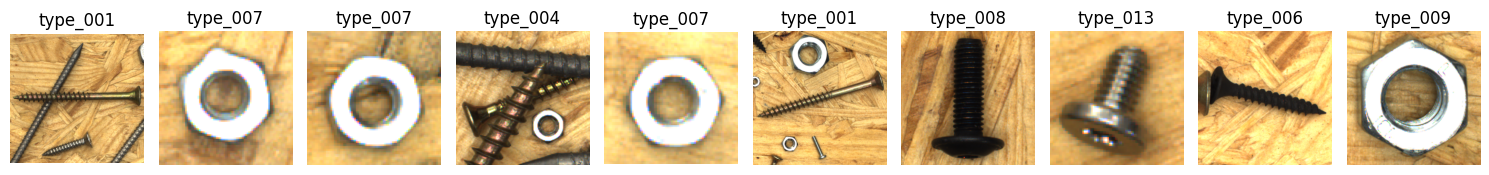

In [3]:
import matplotlib.pyplot as plt
import random
import glob

def visualizar_recortes_aleatorios(output_dir="dataset_recortado", num_samples=10):
    all_images = glob.glob(os.path.join(output_dir, "*", "*.png"))
    

    # Seleccionar aleatoriamente
    samples = random.sample(all_images, min(len(all_images), num_samples))
    
    plt.figure(figsize=(15, 5))
    for i, img_path in enumerate(samples):
        # Leer imagen
        img = cv2.imread(img_path)
        # IMPORTANTE: OpenCV lee en BGR, Matplotlib muestra en RGB. Hay que convertir.
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        
        # Obtener etiqueta de la carpeta
        label = os.path.basename(os.path.dirname(img_path))
        
        plt.subplot(1, num_samples, i+1)
        plt.imshow(img)
        plt.title(label)
        plt.axis('off')
    
    plt.tight_layout()
    plt.show()

# Ejecutar verificación
visualizar_recortes_aleatorios()

Podemos ver que los recortes se han hecho de manera correcta, pero hay que tener un detalle importante en cuenta, los recortes tienen tamaños variables, las CNN que vamos a entrenar necesita un tamaño de entrada fijo.

Para solucionar este problema, cuando vayamos a entrenar el modelo, redimensionaremos los datos. Otra opcion seria haz realizar los recortes en la funcion de arriba, forzar su redimensionado. Pero me quedo con la primera opcion ya que esto nos da flexibilidad para experimentar, ya que dependiendo del modelo que vayamos a usar, el tamaño de entrada es distinto y habria que volver a hacer los recortes.



### Creacion de dataset y conjuntos de train, test y val

In [ ]:
import os
import pandas as pd
from sklearn.model_selection import train_test_split
import glob

# --- CONFIGURACIÓN ---
DATASET_DIR = "dataset_recortado"
SEED = 42 

def crear_splits():
    # 1. Obtener todas las rutas de las imágenes
    # Buscamos recursivamente: dataset_recortado/categoria/imagen.png
    file_paths = glob.glob(os.path.join(DATASET_DIR, "*", "*.png"))
    
    if len(file_paths) == 0:
        print("ERROR: No se encontraron imágenes. Revisa la ruta.")
        return None, None, None

    # 2. Extraer etiquetas 
    labels = [os.path.basename(os.path.dirname(fp)) for fp in file_paths]

    # 3. Crear un DataFrame inicial
    df = pd.DataFrame({
        'filepath': file_paths,
        'label': labels
    })

    print(f"Total de imágenes encontradas: {len(df)}")
    
    # 4. Primera división: Train (70%) vs Temp (30%)
    # Usamos 'stratify' para asegurar que haya la misma proporción de clases en todos los sets
    train_df, temp_df = train_test_split(
        df, 
        test_size=0.3, 
        random_state=SEED, 
        stratify=df['label']
    )

    # 5. Segunda división: Temp se divide en Validation (15%) y Test (15%)
    # Como temp es el 30% del total, al dividirlo a la mitad (0.5), obtenemos 15% y 15% del total
    val_df, test_df = train_test_split(
        temp_df, 
        test_size=0.5, 
        random_state=SEED, 
        stratify=temp_df['label']
    )

    print(f"-----------------------------------")
    print(f"Train set: {len(train_df)} imágenes")
    print(f"Val set:   {len(val_df)} imágenes")
    print(f"Test set:  {len(test_df)} imágenes")
    print(f"-----------------------------------")
    
    return train_df, val_df, test_df

# Ejecutar la función
df_train, df_val, df_test = crear_splits()


Total de imágenes encontradas: 4427
-----------------------------------
Train set: 3098 imágenes
Val set:   664 imágenes
Test set:  665 imágenes
-----------------------------------


## BLOQUE 2: Pipeline de Datos, Configuración del Modelo y entrenamiento del modelo
**Objetivo**: En este bloque transformamos las rutas de las imágenes en tensores numéricos y construimos la arquitectura de red neuronal que aprenderá a clasificarlos.

Este bloque realiza lo siguiente:

Eleccion del modelo

Definición de Transformaciones: Configura el redimensionado de imágenes y aplica Data Augmentation (rotaciones y cambios de luz) al set de entrenamiento para mejorar la robustez.

Creación de Generadores (DataLoaders): Convierte los DataFrames en flujos de datos por lotes (batches), normalizando los píxeles para que la red pueda procesarlos eficientemente.

Carga del Modelo Pre-entrenado: Descarga del modelo 

Entrenamiento del modelo.


#### Eleccion del modelo

Antes de nada hay que seleccionar el modelo para entrenar, el objetivo es encontrar el equilibrio entre precision y coste computacional.

- MobileNet -> Esta arquitectura es la mas ligera de las tres, pero la que mayor velocidad de inferencia nos proporciona (3.5 M de parametros)
- ResNet -> La arquitectura mas pesada de las tres, muy robusta a los detalles (25.6 M de parametros).
- EfficientNet -> Es la arquitectura que mejor ratio precision/parametros tiene. (5.3 M de parametros).

Vamos a usar el modelo ResNet, principalmente por los recursos hardware disponibles.

Tambien,ResNet, permite que la red sea muy profunda, por lo que la sprimeras capas pueden aprender texturas muy básicas y las últimas capas conceptos muy abstractos (clases de tornillos) sin perder información por el camino.

Su robustez hace que el modelo se adapte bien a nuevas tareas con mas facilidad que los demas.

#### Redimensionado de imagenes

Como hemos dicho antes, la capa de entrada del modelo solo acepta un tamaño de entrada, en el caso de ResNet el tamaño de entrada es de 224 x 224.

Tambien debemos normalizar, usando la media y desviacion tipica.

En el caso del conjunto de train, he añadido rotaciones y cambios de luz (Data Augmentation) para simular que tenemos mas datos y asi evitamos que el modelo memorice la posicion exacta del tornillo.

Fuente: https://pytorch.org/hub/pytorch_vision_resnet/

In [ ]:

IMG_SIZE = 224 
BATCH_SIZE = 32

# Valores de normalización oficiales de ImageNet 
mean_imagenet = [0.485, 0.456, 0.406]
std_imagenet = [0.229, 0.224, 0.225]

data_transforms = {
    'train': transforms.Compose([
        transforms.Resize((IMG_SIZE, IMG_SIZE)), # Redimensionar a 224x224
        transforms.RandomRotation(15),           # Data Augmentation: Rotar levemente (+-15 grados)
        transforms.RandomHorizontalFlip(),       # Data Augmentation: Espejo horizontal
        transforms.ColorJitter(brightness=0.1),  # Data Augmentation: Leve cambio de brillo
        transforms.ToTensor(),                   # Convertir imagen a Tensor (0-1)
        transforms.Normalize(mean_imagenet, std_imagenet) # Normalizar 
    ]),
    'val': transforms.Compose([
        transforms.Resize((IMG_SIZE, IMG_SIZE)), # Solo redimensionar
        transforms.ToTensor(),
        transforms.Normalize(mean_imagenet, std_imagenet)
    ]),
    'test': transforms.Compose([
        transforms.Resize((IMG_SIZE, IMG_SIZE)), # Solo redimensionar
        transforms.ToTensor(),
        transforms.Normalize(mean_imagenet, std_imagenet)
    ]),
}



#### Carga y Vectorizacion de Datos en memoria

Abandonamos la lectura de disco y cargamos todo el dataset directamente en la memoria RAM para acelerar el entrenamiento.

Iteramos sobre cada ruta de archivo, aplicamos las transformaciones definidas anteriormente (Redimensionado a 224x224 y Normalización) y convertimos los datos en dos estructuras:

- X (Tensores de Imágenes): Matriz 4D con dimensiones [N_imágenes, 3_canales, 224, 224].

- y (Tensores de Etiquetas): Vector con los índices numéricos de las clases (targets).



In [6]:
import torch
from PIL import Image
from tqdm import tqdm 

# Mapeo de Etiquetas (Texto -> Número)
classes = sorted(df_train['label'].unique())
class_to_idx = {cls_name: i for i, cls_name in enumerate(classes)}

def cargar_imagenes_a_tensores(dataframe, transform):
    """
    Lee las rutas del dataframe, abre las imágenes, aplica resize/normalize
    y devuelve dos Tensores de PyTorch: X (imágenes) e y (etiquetas).
    """
    lista_tensores = []
    lista_labels = []
        
    # Iteramos por cada fila del DataFrame
    for index, row in tqdm(dataframe.iterrows(), total=len(dataframe)):
        ruta = row['filepath']
        etiqueta_texto = row['label']
        
        # Cargar imagen y convertir a RGB
        img = Image.open(ruta).convert('RGB')
        
        #  Aplicar transformaciones (Resize, Normalización, etc.)
        # Esto convierte la imagen en un tensor de forma [3, 224, 224]
        img_tensor = transform(img)
        
        # Guardar en listas temporales
        lista_tensores.append(img_tensor)
        lista_labels.append(class_to_idx[etiqueta_texto])
        
    # Stack cn todas las imágenes en un solo Tensor gigante
    X = torch.stack(lista_tensores)
    y = torch.tensor(lista_labels)
    
    return X, y


print("\n CARGANDO TRAIN ")
X_train, y_train = cargar_imagenes_a_tensores(df_train, data_transforms['train'])

print("\n CARGANDO VAL ")
X_val, y_val = cargar_imagenes_a_tensores(df_val, data_transforms['val'])

print("\n CARGANDO TEST")
X_test, y_test = cargar_imagenes_a_tensores(df_test, data_transforms['test'])

# Verificación Final 
print(f"X_train shape: {X_train.shape} (Imágenes)")
print(f"y_train shape: {y_train.shape} (Etiquetas)")



 CARGANDO TRAIN 


100%|██████████| 3098/3098 [00:31<00:00, 96.94it/s] 



 CARGANDO VAL 


100%|██████████| 664/664 [00:05<00:00, 117.90it/s]



 CARGANDO TEST


100%|██████████| 665/665 [00:06<00:00, 106.26it/s]

X_train shape: torch.Size([3098, 3, 224, 224]) (Imágenes)
y_train shape: torch.Size([3098]) (Etiquetas)


#### Descarga del modelo

Vamos a descargar el modelo ResNet50, congelamos las primeras 49 capas porque solo necesitamos modificar la utlima capa, ya que esta por defecto clasifica 1000 objets. En la nueva capa solo tendra salidas para nuestras distintas piezas que queremos clasificar

In [7]:
import torch
import torch.nn as nn
from torchvision import models

#  Descargar el Modelo Pre-entrenado 
model = models.resnet50(weights='DEFAULT')

# CONGELAR PESOS
# Iteramos por todos los parámetros de la red original y desactivamos el gradiente.
for param in model.parameters():
    param.requires_grad = False

# MODIFICAR LA CAPA FINAL 
# Obtenemos el número de neuronas que entran a la última capa 
num_features = model.fc.in_features 

# Obtenemos el numero de clases (son 13 pero para asegurarnos que no fallamos)
num_classes = len(classes) 

# Reemplazamos la capa 'fc' (Fully Connected) por una nueva.
# Al ser nueva, esta SÍ tiene requires_grad=True por defecto (se entrenará).
model.fc = nn.Linear(num_features, num_classes)

# Mover el modelo a la cpu ---
model = model.to('cpu')


print(f"Capa de entrada final: {num_features} neuronas")
print(f"Capa de salida final:  {num_classes} neuronas")


Capa de entrada final: 2048 neuronas
Capa de salida final:  13 neuronas


#### Entrenamiento del modelo


Para elentrenamiento si que usamos gpu, ya nos acelera mucho el tiempo de ejecucion, para otras tareas simples, como la anterior, usando la cpu tabmien es muy rapido.

In [ ]:
import torch.optim as optim
import numpy as np
import torch.nn as nn
import torch
from tqdm import tqdm 


# Configuracion para usar gpu en el entrenamiento
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Entrenando usando: {device}")

# Configuracion de hiperparametros
LR = 0.001          
EPOCHS = 10         
BATCH_SIZE = 32     

# Movemos el modelo a GPU
model = model.to(device)

# CrossEntropyLoss para clasificación múltiple
criterion = nn.CrossEntropyLoss()

# Optimizador: Adam 
optimizer = optim.Adam(model.fc.parameters(), lr=LR)

# Entrenamiento del modelo
print(f"Iniciando entrenamiento...")

history = {'train_loss': [], 
           'train_acc': [], 
           'val_loss': [], 
           'val_acc': []}

for epoch in range(EPOCHS):
    model.train() 
    
    running_loss = 0.0
    correct = 0
    total = 0
    
    # Fase de Entrenamiento 
    n_samples = len(X_train)
    
    # Barajar datos antes de cada época
    indices = torch.randperm(n_samples)
    X_shuffled = X_train[indices]
    y_shuffled = y_train[indices]
    
    pbar = tqdm(range(0, n_samples, BATCH_SIZE), desc=f"Epoch {epoch+1}/{EPOCHS}")
    
    for i in pbar:
        # 1. Crear el batch y mandarlo a GPU (.to(device))
        X_batch = X_shuffled[i : i + BATCH_SIZE].to(device)
        y_batch = y_shuffled[i : i + BATCH_SIZE].to(device)
        
        # 2. Resetear gradientes
        optimizer.zero_grad()
        
        # 3. Predicción (Forward)
        outputs = model(X_batch)
        
        # 4. Calcular error (Loss)
        loss = criterion(outputs, y_batch)
        
        # 5. Aprender (Backward + Step)
        loss.backward()
        optimizer.step()
        
        # Estadísticas
        running_loss += loss.item() * X_batch.size(0)
        _, predicted = torch.max(outputs, 1)
        total += y_batch.size(0)
        correct += (predicted == y_batch).sum().item()
        
        # Actualizamos la barra
        pbar.set_postfix({'loss': loss.item()})
        
    epoch_loss = running_loss / n_samples
    epoch_acc = correct / total
    
    # Fase de Validación 
    model.eval()
    val_loss = 0.0
    val_correct = 0
    val_total = 0
    
    with torch.no_grad():
        n_val = len(X_val)
        for i in range(0, n_val, BATCH_SIZE):
            # Mandar validación también a GPU
            X_batch = X_val[i : i + BATCH_SIZE].to(device)
            y_batch = y_val[i : i + BATCH_SIZE].to(device)
            
            outputs = model(X_batch)
            loss = criterion(outputs, y_batch)
            
            val_loss += loss.item() * X_batch.size(0)
            _, predicted = torch.max(outputs, 1)
            val_total += y_batch.size(0)
            val_correct += (predicted == y_batch).sum().item()
            
    val_loss = val_loss / n_val
    val_acc = val_correct / n_val
    
    #Guardar Resultados 
    history['train_loss'].append(epoch_loss)
    history['train_acc'].append(epoch_acc)
    history['val_loss'].append(val_loss)
    history['val_acc'].append(val_acc)
    
    tqdm.write(f"Epoch [{epoch+1}/{EPOCHS}] "
          f"Train Loss: {epoch_loss:.4f} Acc: {epoch_acc:.4f} | "
          f"Val Loss: {val_loss:.4f} Acc: {val_acc:.4f}")

Entrenando usando: cuda
Iniciando entrenamiento...


Epoch 1/10: 100%|██████████| 97/97 [00:06<00:00, 15.14it/s, loss=0.747]


Epoch [1/10] Train Loss: 1.3114 Acc: 0.7628 | Val Loss: 0.8329 Acc: 0.8434


Epoch 2/10: 100%|██████████| 97/97 [00:05<00:00, 16.91it/s, loss=0.436]


Epoch [2/10] Train Loss: 0.5548 Acc: 0.9216 | Val Loss: 0.5462 Acc: 0.8810


Epoch 3/10: 100%|██████████| 97/97 [00:05<00:00, 16.91it/s, loss=0.407]


... (11 outputs left out)

Epoch 9/10: 100%|██████████| 97/97 [00:05<00:00, 16.83it/s, loss=0.0614]


Epoch [9/10] Train Loss: 0.1383 Acc: 0.9793 | Val Loss: 0.2106 Acc: 0.9398


Epoch 10/10: 100%|██████████| 97/97 [00:05<00:00, 16.85it/s, loss=0.277] 


Epoch [10/10] Train Loss: 0.1286 Acc: 0.9832 | Val Loss: 0.2132 Acc: 0.9337


#### Visualizacion

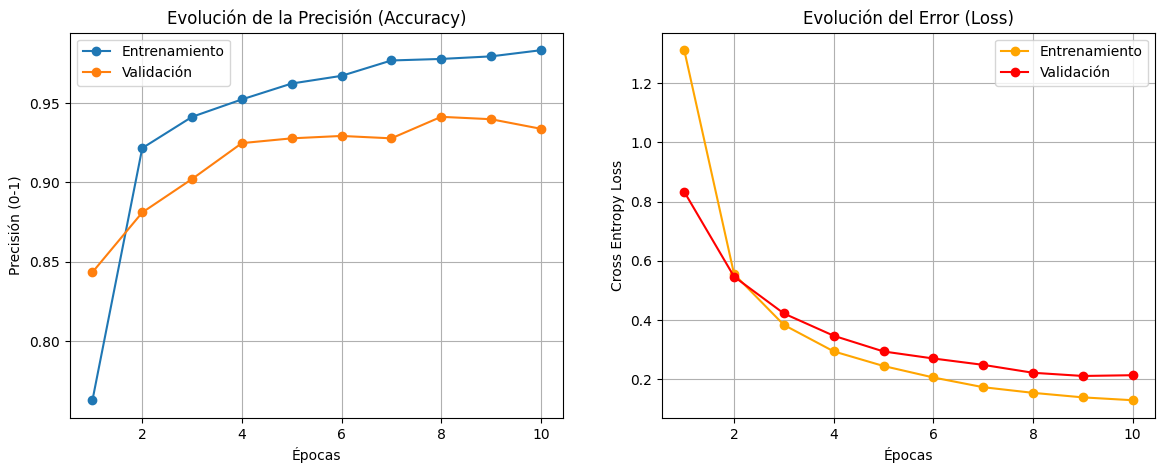

In [9]:
import matplotlib.pyplot as plt

# Extraer datos
acc = history['train_acc']
val_acc = history['val_acc']
loss = history['train_loss']
val_loss = history['val_loss']
epochs_range = range(1, len(acc) + 1)

# Crear figura
plt.figure(figsize=(14, 5))

# Gráfica 1: Precisión (Accuracy)
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Entrenamiento', marker='o')
plt.plot(epochs_range, val_acc, label='Validación', marker='o')
plt.title('Evolución de la Precisión (Accuracy)')
plt.xlabel('Épocas')
plt.ylabel('Precisión (0-1)')
plt.legend()
plt.grid(True)

# Gráfica 2: Pérdida (Loss)
plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Entrenamiento', marker='o', color='orange')
plt.plot(epochs_range, val_loss, label='Validación', marker='o', color='red')
plt.title('Evolución del Error (Loss)')
plt.xlabel('Épocas')
plt.ylabel('Cross Entropy Loss')
plt.legend()
plt.grid(True)

plt.show()

**Evolucion del accuracy**:

- Podemos ver como el entrenamiento alcanza un precision de 99% y la validacion alcanza un 94%, esta diferencia se debe a que los datos de validacion son mas dificiles para el modelo ya qe nunca los ha visto, pero la tendencia general es subir.

**Evolucion del loss**

- Vemos que el modelo aprende rapido ya que la linea de train cae bastante rapido, en cuanto a la linea de validacion, vemos que baja de manera constante junto con la de train. Como detalle, remarcar que en las ultimas epocas, la linea de val se empieza aplanar, estoi significa que el modelo esta llegando a su limite de aprendizaje con respecto a los datos actuales, si hubiesemos puesto mas epocas, es muy probable qu eel modelo hubiese empezado a memorizar a fallar en la validacion.

## Bloque 3 - Dimensionamiento del Sistema de Visión 
Para cumplir con los requisitos operativos de la línea y asegurar la calidad, hemos realizado los siguientes cálculos para seleccionar cámara y óptica.

### 1.1. Cálculo de la Resolución Espacial
El requisito de calidad dice que la tuerca más pequeña (6 mm) debe verse con **135 píxeles**. Esto define el factor de escala:

Resolución = 6 mm / 135 px = 0.0444 mm/px

Esto implica que cada píxel de la imagen representa unas **44.4 micras** del objeto real.

### 1.2. Selección del Sensor
Para cubrir el ancho de cinta manteniendo esa resolución, seleccionamos un sensor estándar de **5 Megapíxeles** (resolución de 2448 x 2048 píxeles).

Con esta resolución, el Campo de Visión (FOV) resultante es:
* **Ancho:** 2448 px * 0.0444 mm/px = **108 mm**
* **Alto:** 2048 px * 0.0444 mm/px = **91 mm**

Un área de inspección de aprox. 110 x 90 mm es adecuada.

**Importante:** Dado que la cinta se mueve a 1 m/s, es obligatorio usar una cámara con sensor **Global Shutter**. Un Rolling Shutter deformaría las piezas y no serviría.

### 1.3. Cálculo del Tiempo de Exposición
Para evitar que la imagen salga borrosa (motion blur), el objeto no debe moverse más de 1 píxel (0.0444 mm) mientras el obturador está abierto.

* Velocidad (V): 1000 mm/s
* Píxel (P): 0.0444 mm

t_exp <= 0.0444 / 1000 = 0.0000444 s
$$t_{exp} \le 44 \mu s$$

**Conclusión:** El tiempo de exposición máximo debe ser de **44 microsegundos**. Esto requerirá iluminación artificial muy potente.

### 1.4. Cálculo de la Óptica (Lente)
Fijamos la distancia de trabajo (WD) en **600 mm**.
Considerando una cámara con sensor formato 2/3" (ancho aprox 8.8 mm), calculamos la distancia focal (f):

f = (Ancho_sensor * WD) / FOV_ancho
f = (8.8 mm * 600 mm) / 108 mm = 48.8 mm

La focal teórica es de 48.8 mm. La lente comercial estándar más cercana es de **50 mm**. Al ser ligeramente mayor, bastará con alejar un poco la cámara (a unos 615 mm).
$$f = \frac{8.8 \text{ mm} \times 600 \text{ mm}}{108 \text{ mm (FOV)}} \approx 48.8 \text{ mm}$$
### 1.5. Selección de Equipo y Presupuesto
Propuesta de hardware comercial basada en los cálculos:

* **Cámara:** Basler ace 2 (Modelo a2A2448-75ucBAS). Sensor Sony IMX264 (5MP), Global Shutter. Precio: ~ 500 €
* **Óptica:** Computar M5028-MPW3. Focal 50mm, Formato 2/3". Precio: ~ 180 €
* **Iluminación:** Anillo LED Industrial de alta intensidad (luz blanca). Precio: ~ 120 €

**TOTAL ESTIMADO:** ~ 800 €

#### Fuentes

- Camara (Justifacion): https://docs.baslerweb.com/aca2440-35uc
- Precio Lente: https://machinevisiondirect.com/products/computar-m5028-mpw3
- Precio anillo LED: https://shop.led2work.com/en?gad_source=1&gad_campaignid=20275483593&gbraid=0AAAAACyoSIOey6-zUavPUnTbaMIh0Oy0D&gclid=Cj0KCQiAgbnKBhDgARIsAGCDdldKu5_oXNFc4p6Zw9PXGXr3TnZ9Sbr0pEVqjvbXimHUSR_652QJqq0aAoMVEALw_wcB
- Precio Camara:https://industrymall.de/es/sensoren/21982-basler-aca1920-25gm-106493-10-camera.html?gad_source=1

## Bloque 4 - Inferencia, Persistencia y Resultados

**Objetivo**: En este bloque mostramos el rendimiento definitivo del modelo ya entrenado utilizando datos desconocidos, aseguramos su conservación y visualizamos su funcionamiento en un entorno real.

- Evaluacion en el conjunto de test
- Guardar el modelo -> Guardamos los pesos y parametros aprendidos para no tener que volver a entrenar el modelo cada vez que queramos usarlo.
- Visualizacion de los resultados.

#### Evaluacion en el conjunto de test

In [13]:
import torch

model.eval() 

correct = 0
total = 0

# Mover datos de test a la GPU
X_test = X_test.to(device)
y_test = y_test.to(device)

with torch.no_grad():
    # Sklearn necesita que los datos estén en CPU y formato Numpy (no Tensores GPU)
    y_true_np = y_test.cpu().numpy()
    y_pred_np = predicted.cpu().numpy()

# Ordenamos el diccionario por su índice (0, 1, 2...)
nombres_clases = [k for k, v in sorted(class_to_idx.items(), key=lambda item: item[1])]

print("Metricas de clasificacion:")
print(classification_report(y_true_np, y_pred_np, target_names=nombres_clases))


Metricas de clasificacion:
              precision    recall  f1-score   support

    type_001       0.69      0.98      0.81        47
    type_002       1.00      0.83      0.91        47
    type_003       0.95      0.73      0.82        48
    type_004       0.91      0.87      0.89        47
    type_005       0.92      0.95      0.93        58
    type_006       0.98      0.97      0.97        59
    type_007       1.00      0.91      0.95        55
    type_008       0.98      0.98      0.98        55
    type_009       1.00      0.96      0.98        48
    type_010       0.91      1.00      0.95        52
    type_011       0.96      1.00      0.98        52
    type_012       1.00      0.96      0.98        49
    type_013       0.96      1.00      0.98        48

    accuracy                           0.94       665
   macro avg       0.94      0.93      0.93       665
weighted avg       0.94      0.94      0.94       665



Los resultados demuestran que el modelo es altamente robusto, alcanzando una exactitud global del 94%, con un rendimiento casi perfecto en la mayoría de las categorías (especialmente en type_008, type_011 y type_013). Sin embargo, existen dos puntos débiles localizados: el type_001, que sufre de baja precisión (0.69) —indicando que el modelo genera muchos "falsos positivos" y confunde otras clases con esta—, y el type_003, que tiene el recall más bajo (0.73), lo que significa que el sistema está fallando en detectar una parte considerable de los casos reales de este tipo. A pesar de estas anomalías específicas, los promedios macro y ponderados confirman que el clasificador es muy confiable para el conjunto general.

#### Guardar el modelo

In [11]:
ruta_modelo = "modelo_tornillos_resnet50.pth"
torch.save(model.state_dict(), ruta_modelo)
print(f"Guardado en: {ruta_modelo}")

Guardado en: modelo_tornillos_resnet50.pth


#### Visualizacion de los resultados

Por último, vamos a ver una demostración visual del modelo en acción. Seleccionamos 3 imágenes al azar del conjunto de test para comprobar si las clasifica bien. Si el título aparece en color verde, significa que el modelo ha acertado la predicción; si sale en rojo, es que se ha equivocado.

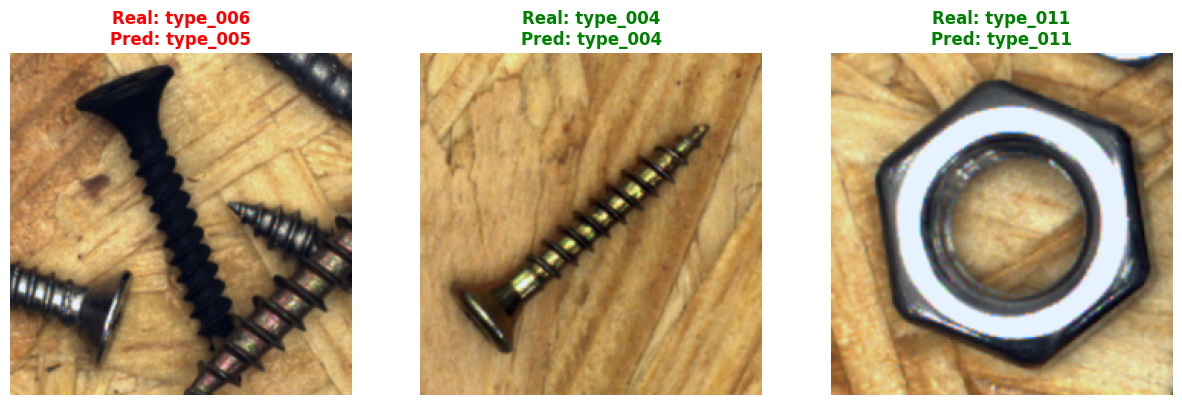

In [ ]:
# Diccionario inverso para etiquetas
idx_to_class = {v: k for k, v in class_to_idx.items()}
indices = random.sample(range(len(X_test)), 3)

plt.figure(figsize=(15, 5))

for i, idx in enumerate(indices):
    # Predicción
    img_tensor = X_test[idx].unsqueeze(0).to(device)
    label_real = y_test[idx].item()
    
    with torch.no_grad():
        output = model(img_tensor)
        _, pred = torch.max(output, 1)
        label_pred = pred.item()
        
    # Visualización
    img_plot = X_test[idx].cpu().permute(1, 2, 0).numpy()
    # Des-normalizar para ver bien los colores (aprox)
    img_plot = (img_plot - img_plot.min()) / (img_plot.max() - img_plot.min())
    
    plt.subplot(1, 3, i + 1)
    plt.imshow(img_plot)
    plt.axis('off')
    
    titulo = f"Real: {idx_to_class[label_real]}\nPred: {idx_to_class[label_pred]}"
    color = 'green' if label_real == label_pred else 'red'
    plt.title(titulo, color=color, fontweight='bold')

plt.show()


En cada ejecucion vemos unas piezas distintas, pero he decidido quedarme con esta ejecucion ya que muestra un fallo del modelo, lo que demuestra que por muy bueno que haya sido el entrenamiento, pre-procesamiento... el modelo no esperfecto y se equivocara, pero en general clasifica muy bien y es robusto.